In [56]:
import pandas as pd

# 1. 讀取 CSV 檔案
csv_file = 'ref.csv' 
df = pd.read_csv(csv_file)

# 2. 定義異常判斷欄位
group1_cols = ['AR', 'AS', 'PR', 'PS', 'TR', 'TS', 'MR', 'MS', 'MVP']
#group2_cols = ['HTN', 'VPC', 'AF', 'PPM']
group2_cols = ['HTN',  'PPM']
g1_exist = [col for col in group1_cols if col in df.columns]
g2_exist = [col for col in group2_cols if col in df.columns]

# 3. 執行異常篩選邏輯
mask1 = df[g1_exist].isin(['S', 'M', 's', 'm']).any(axis=1)
mask2 = df[g2_exist].isin([1, '1', 1.0]).any(axis=1)
abnormal_mask = mask1 | mask2

# 4. 取得不重複的病人編號集合 (轉為整數確保排序正確)
all_numbers = set(df['number'].dropna().astype(int))
abnormal_numbers_set = set(df.loc[abnormal_mask, 'number'].dropna().astype(int))
normal_numbers_set = all_numbers - abnormal_numbers_set

# 5. 格式化為字串 (使用頓號 "、" 串接)
normal_str = ', '.join(map(str, sorted(normal_numbers_set)))
abnormal_str = ', '.join(map(str, sorted(abnormal_numbers_set)))

# 6. 組合最終內容
final_content = f"normal:{normal_str} abnormal:{abnormal_str}"

# 7. 寫入 txt 檔案
output_filename = 'patient_classification.txt'
with open(output_filename, 'w', encoding='utf-8') as f:
    f.write(final_content)

print(f"🎉 已成功產出檔案：{output_filename}")
print("內容預覽：")
print(final_content)

🎉 已成功產出檔案：patient_classification.txt
內容預覽：
normal:1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 30, 31, 34, 35, 39, 44, 46, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 61, 63, 69, 72, 78, 82, 83, 85, 93, 100, 101, 102, 103, 104, 116, 117, 118, 121 abnormal:22, 23, 24, 25, 26, 27, 28, 29, 32, 33, 36, 37, 38, 40, 41, 42, 43, 45, 47, 48, 60, 62, 64, 65, 66, 67, 68, 70, 71, 73, 74, 75, 76, 77, 79, 80, 81, 84, 86, 87, 88, 89, 90, 91, 92, 94, 95, 96, 97, 98, 99, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 119, 120, 122, 123, 124, 125


In [ ]:
import pandas as pd

# 1. 設定你的 CSV 檔案路徑 
# 2. 貼上你的正常與異常名單
 
 
normal_list  = [ 34, 35, 37, 44, 45, 47, 48, 49, 51, 52, 53, 54, 55, 
                     56, 57, 58, 59, 63, 65, 66, 67, 68, 69, 71, 72, 77, 78, 79, 81, 82, 
                     83, 84, 85, 86, 87, 88, 89, 92, 95, 96, 99, 100, 101, 102, 103, 104, 
                     116, 121, 122 ] 
abnormal_list  = [36, 38, 39, 40, 41, 42, 43, 
                  46, 50, 60, 61, 62, 64, 70, 73, 74, 75, 76, 80, 90, 91, 93, 94, 97, 
                  98, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 117, 118, 
                  119, 120, 123, 124, 125]
# 3. 處理 number 轉型防呆，並計算 label
df['number_int'] = pd.to_numeric(df['number'], errors='coerce').fillna(-1).astype(int)

# 預設 label 為 '2' (未知)
df['label'] = '2'

# 標記 0 (正常) 與 1 (異常)
df.loc[df['number_int'].isin(normal_list), 'label'] = '0'
df.loc[df['number_int'].isin(abnormal_list), 'label'] = '1'

# 4. 準備輸出的資料 (只取 file 和 label 兩欄)
# 假設你的檔名在第一欄 (iloc[:, 0])，如果你的檔名欄位有特定名稱(例如 'Filename')，
# 可以改成 df['Filename']
output_df = pd.DataFrame({
    'file': df.iloc[:, 0], 
    'label': df['label']
})

# 5. 印出各狀態的數量，確認是否有漏網之魚 (標記為 '2' 的)
print("========== Label 分類統計 ==========")
print(output_df['label'].value_counts())
print("====================================")

# 預覽前 5 筆資料確認格式
print("\n預覽輸出的檔案內容：")
print(output_df.head())

# 6. 將結果另存成只有兩欄的 CSV 檔案
output_file = 'Label.csv'
output_df.to_csv(output_file, index=False, encoding='utf-8-sig')

print(f"\n🎉 處理完成！已產出乾淨的 2-column 標籤檔: {output_file}")

========== Label 分類統計 ==========
label
1    711
0    539
2    320
Name: count, dtype: int64

預覽輸出的檔案內容：
                  file label
0  2024_09_30_09_15_51     2
1  2024_09_30_09_17_00     2
2  2024_09_30_09_29_03     2
3  2024_09_30_09_29_54     2
4  2024_09_30_10_25_33     2

🎉 處理完成！已產出乾淨的 2-column 標籤檔: Label.csv


In [ ]:
import os
import glob
import wfdb
import numpy as np
import pandas as pd  # 新增 pandas 用來讀取 CSV
from scipy import signal

# ================= 1. 檢查路徑與工作目錄 =================
print("--- 路徑檢查 ---")
current_dir = os.getcwd()
print(f"1. 當前 Jupyter 執行目錄: {current_dir}")

BASE_DIR = './' 
ECG_DIR = os.path.join(BASE_DIR, 'ECG_DAT')
PCG_DIR = os.path.join(BASE_DIR, 'PCG_DAT')
OUT_DIR = os.path.join(BASE_DIR, 'CNN_INPUT')
LABEL_CSV = os.path.join(BASE_DIR, 'Label.csv')  # 設定 Label.csv 的路徑

print(f"2. 預期 ECG 資料夾路徑: {ECG_DIR}")
print(f"3. 預期 PCG 資料夾路徑: {PCG_DIR}")
print(f"4. 預期標籤 CSV 路徑: {LABEL_CSV}")

if not os.path.exists(ECG_DIR):
    print("❌ 錯誤：找不到 ECG_DAT 資料夾！")
if not os.path.exists(LABEL_CSV):
    print("❌ 錯誤：找不到 Label.csv 檔案！請確認檔案位置。")

# ================= 2. 讀取標籤對照表 (Label.csv) =================
print("\n--- 讀取標籤對照表 ---")
df_labels = pd.read_csv(LABEL_CSV)

# 為了防止 CSV 裡的檔名帶有副檔名 (如 .hea 或 .wav)，我們統一清掉副檔名當作 key
df_labels['clean_file'] = df_labels['file'].astype(str).str.replace(r'\.(hea|wav|dat|mat)$', '', regex=True)

# 建立一個 Dictionary，格式為 { '2024_09_30_09_15_51': 0, ... }，查詢速度最快
label_dict = dict(zip(df_labels['clean_file'], df_labels['label']))
print(f"✅ 成功載入標籤表，共 {len(label_dict)} 筆紀錄。")

# ================= 3. 尋找檔案並處理 =================
print("\n--- 尋找檔案 ---")
search_pattern = os.path.join(ECG_DIR, '*.hea')
ecg_records = glob.glob(search_pattern)

print(f"共找到 {len(ecg_records)} 個 ECG 檔案。")

if len(ecg_records) > 0:
    if not os.path.exists(OUT_DIR):
        os.makedirs(OUT_DIR)
        print(f"✅ 建立輸出資料夾: {OUT_DIR}")

    print("\n--- 開始處理訊號 ---")
    TARGET_POINTS = 720
    WINDOW_SEC = 2.0  # 統一切割長度為 2 秒
    
    for ecg_path in ecg_records:
        # record_name 會是純檔名，例如 '2024_09_30_09_15_51'
        record_name = os.path.basename(ecg_path).replace('.hea', '')
        pcg_record_path = os.path.join(PCG_DIR, record_name)
        ecg_record_path = os.path.join(ECG_DIR, record_name)

        if not os.path.exists(pcg_record_path + '.hea'):
            print(f"⚠️ 跳過 {record_name}: 找不到對應的 PCG 檔案。")
            continue

        print(f"\n讀取中: {record_name} ...")
         
        if record_name not in label_dict:
            print(f"⚠️ 跳過 {record_name}: 在 Label.csv 中找不到這筆檔名的標籤！")
            continue
            
        # 取出標籤，並確保轉成整數 (防呆：csv 讀出來可能是字串 '0' 或 '1')
        label = int(label_dict[record_name])
        
        if label == 0:
            step_sec = 2.0  # 正常資料：0.5秒擴增
            print(f"  -> 查表結果: 🟢 正常資料 (Label:0, 步長:{step_sec}s)")
        elif label == 1:
            step_sec = 2.0  # 異常資料：2.0秒不擴增
            print(f"  -> 查表結果: 🔴 異常資料 (Label:1, 步長:{step_sec}s)")
        else:
            print(f"⚠️ 跳過 {record_name}: 標籤為 {label} (非 0 亦非 1)，不處理。")
            continue

        # ---------------------------------------------------------
        # 讀取與切割訊號
        # ---------------------------------------------------------
        try:
            sig_ecg, meta_ecg = wfdb.rdsamp(ecg_record_path)
            sig_pcg, meta_pcg = wfdb.rdsamp(pcg_record_path)
        except Exception as e:
            print(f"❌ 讀取 WFDB 失敗 ({record_name}): {e}")
            continue
        
        ecg_1d = sig_ecg[:, 0]
        pcg_1d = sig_pcg[:, 0]
        
        fs_ecg = meta_ecg['fs']
        fs_pcg = meta_pcg['fs']
        
        total_seconds = min(len(ecg_1d)/fs_ecg, len(pcg_1d)/fs_pcg)
        
        current_time = 0.0  
        seg_idx = 0         
        
        while current_time + WINDOW_SEC <= total_seconds:
            start_ecg = int(current_time * fs_ecg)
            end_ecg = int((current_time + WINDOW_SEC) * fs_ecg)
            
            start_pcg = int(current_time * fs_pcg)
            end_pcg = int((current_time + WINDOW_SEC) * fs_pcg)
            
            chunk_ecg = signal.resample(ecg_1d[start_ecg:end_ecg], TARGET_POINTS)
            chunk_pcg = signal.resample(pcg_1d[start_pcg:end_pcg], TARGET_POINTS)
            
            combined = np.vstack((chunk_ecg, chunk_pcg))
            
            # 檔名依然保留 label 資訊，方便後續訓練讀取
            out_name = os.path.join(OUT_DIR, f"{record_name}_seg_{seg_idx:04d}.npy")
            np.save(out_name, combined)
            
            current_time += step_sec
            seg_idx += 1
            
        print(f"  ✅ {record_name} 處理完成！共切出 {seg_idx} 個 2 秒片段。")

--- 路徑檢查 ---
1. 當前 Jupyter 執行目錄: c:\Users\USER\Desktop\test_env\dataset_github
2. 預期 ECG 資料夾路徑: ./ECG_DAT
3. 預期 PCG 資料夾路徑: ./PCG_DAT
4. 預期標籤 CSV 路徑: ./Label.csv

--- 讀取標籤對照表 ---
✅ 成功載入標籤表，共 1569 筆紀錄。

--- 尋找檔案 ---
共找到 1569 個 ECG 檔案。
✅ 建立輸出資料夾: ./CNN_INPUT

--- 開始處理訊號 ---

讀取中: 2024_09_30_09_15_51 ...
⚠️ 跳過 2024_09_30_09_15_51: 標籤為 2 (非 0 亦非 1)，不處理。

讀取中: 2024_09_30_09_17_00 ...
⚠️ 跳過 2024_09_30_09_17_00: 標籤為 2 (非 0 亦非 1)，不處理。

讀取中: 2024_09_30_09_29_03 ...
⚠️ 跳過 2024_09_30_09_29_03: 標籤為 2 (非 0 亦非 1)，不處理。

讀取中: 2024_09_30_09_29_54 ...
⚠️ 跳過 2024_09_30_09_29_54: 標籤為 2 (非 0 亦非 1)，不處理。

讀取中: 2024_09_30_10_25_33 ...
⚠️ 跳過 2024_09_30_10_25_33: 標籤為 2 (非 0 亦非 1)，不處理。

讀取中: 2024_09_30_10_25_52 ...
⚠️ 跳過 2024_09_30_10_25_52: 標籤為 2 (非 0 亦非 1)，不處理。

讀取中: 2024_09_30_10_26_19 ...
⚠️ 跳過 2024_09_30_10_26_19: 標籤為 2 (非 0 亦非 1)，不處理。

讀取中: 2024_09_30_10_26_42 ...
⚠️ 跳過 2024_09_30_10_26_42: 標籤為 2 (非 0 亦非 1)，不處理。

讀取中: 2024_09_30_11_24_37 ...
⚠️ 跳過 2024_09_30_11_24_37: 標籤為 2 (非 0 亦非 1)，不處理。

讀取中: 2024_09_30_

正在檢視檔案: 2026_02_12_11_56_21_seg_0006.npy
資料維度 (Shape): (2, 720)


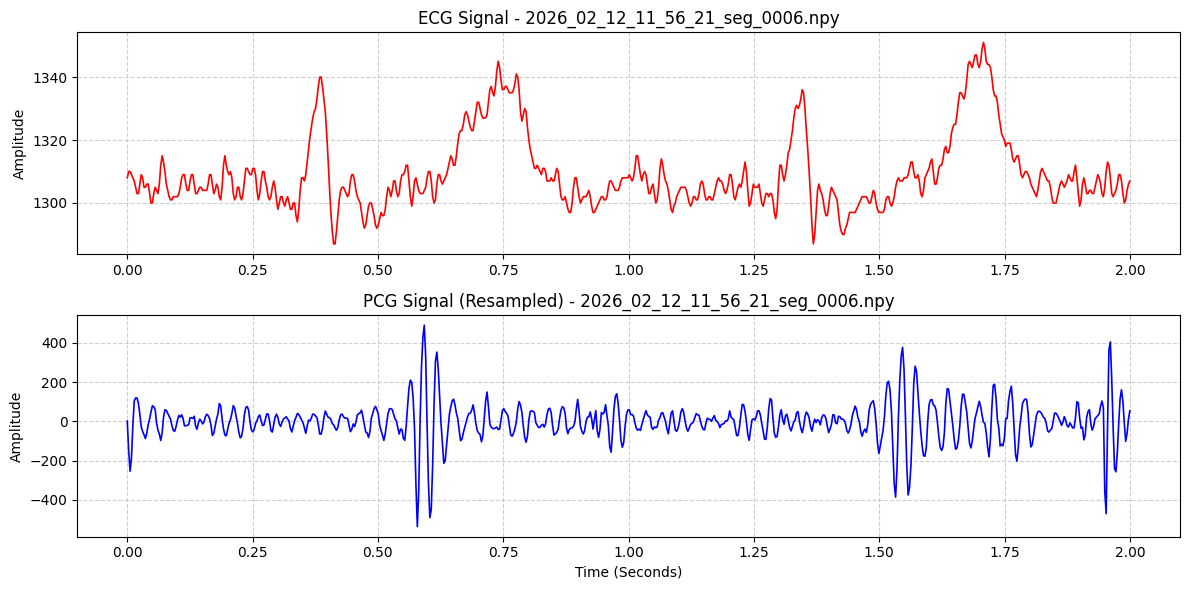

In [51]:
import numpy as np
import matplotlib.pyplot as plt
import os
import glob 
# ================= 1. 抓取一個切好的檔案 =================
OUT_DIR = './CNN_INPUT'
npy_files = glob.glob(os.path.join(OUT_DIR, '2026_02_12_11_56_21_seg_0006.npy'))

if len(npy_files) == 0:
    print("找不到 .npy 檔案，請確認 OUT_DIR 路徑是否正確！")
else:
    # 我們隨便挑清單中的第一個檔案來看看
    sample_file = npy_files[0]
    filename = os.path.basename(sample_file)
    print(f"正在檢視檔案: {filename}")
    
    # ================= 2. 讀取與檢查維度 =================
    data = np.load(sample_file)
    print(f"資料維度 (Shape): {data.shape}")  # 這裡應該要印出 (2, 720)
    
    # 分離兩個 Channel
    ecg_data = data[0, :]  # 第 0 個 channel 是 ECG
    pcg_data = data[1, :]  # 第 1 個 channel 是 PCG
    
    # 建立時間軸：0 到 2 秒，總共 720 個點
    time_axis = np.linspace(0, 2, 720)
    
    # ================= 3. 畫出波形圖 =================
    plt.figure(figsize=(12, 6))
    
    # 畫上半部：ECG
    plt.subplot(2, 1, 1)
    plt.plot(time_axis, ecg_data, color='red', linewidth=1.2)
    plt.title(f'ECG Signal - {filename}')
    plt.ylabel('Amplitude')
    plt.grid(True, linestyle='--', alpha=0.6)
    
    # 畫下半部：PCG
    plt.subplot(2, 1, 2)
    plt.plot(time_axis, pcg_data, color='blue', linewidth=1.2)
    plt.title(f'PCG Signal (Resampled) - {filename}')
    plt.xlabel('Time (Seconds)')
    plt.ylabel('Amplitude')
    plt.grid(True, linestyle='--', alpha=0.6)
    
    # 調整排版並顯示
    plt.tight_layout()
    plt.show()